# 0. Imports

In [1]:
from copy import deepcopy
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from torch_geometric.datasets import TUDataset
from torch_geometric.loader import DataLoader

sys.path.append("..")  # Import model definitions from src/models.py later.

seed = 42
torch.manual_seed(seed)

c:\Users\pablo\Desktop\UPF\Thesis\02_enzymes_classifier\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


# 1. Load the data


In [2]:
dataset = TUDataset(
    root="../data",
    name="ENZYMES",
    use_node_attr=True
)

labels = torch.cat([graph.y for graph in dataset])

print(dataset)
print(f"Graphs: {len(dataset)}")
print(f"Classes: {dataset.num_classes}")
print(f"Features per node: {dataset.num_node_features}")
print(f"Features per edge: {dataset.num_edge_features}")
print(f"Graphs per class: {torch.bincount(labels).tolist()}")

ENZYMES(600)
Graphs: 600
Classes: 6
Features per node: 21
Features per edge: 0
Graphs per class: [100, 100, 100, 100, 100, 100]


In [3]:
graph = dataset[0]

print(graph)
print(f"Nodes: {graph.num_nodes}")
print(f"Edge entries: {graph.num_edges}")
print(f"Node features shape: {tuple(graph.x.shape)}")
print(f"Graph label: {graph.y.item()} | Label shape: {tuple(graph.y.shape)}")

Data(edge_index=[2, 168], x=[37, 21], y=[1])
Nodes: 37
Edge entries: 168
Node features shape: (37, 21)
Graph label: 5 | Label shape: (1,)


# 2. Split the graphs


In [4]:
indices = list(range(len(dataset)))

train_indices, remaining_indices = train_test_split(
    indices,
    test_size=0.2,
    stratify=labels.numpy(),
    random_state=seed
)

val_indices, test_indices = train_test_split(
    remaining_indices,
    test_size=0.5,
    stratify=labels[remaining_indices].numpy(),
    random_state=seed
)

train_dataset = dataset[train_indices]
val_dataset = dataset[val_indices]
test_dataset = dataset[test_indices]

for name, subset in (("Training", train_dataset), ("Validation", val_dataset), ("Test", test_dataset)):
    subset_labels = torch.cat([graph.y for graph in subset])
    counts = torch.bincount(subset_labels, minlength=dataset.num_classes)
    print(f"{name}: {len(subset)} graphs | Per class: {counts.tolist()}")

Training: 480 graphs | Per class: [80, 80, 80, 80, 80, 80]
Validation: 60 graphs | Per class: [10, 10, 10, 10, 10, 10]
Test: 60 graphs | Per class: [10, 10, 10, 10, 10, 10]


In [5]:
from sklearn.preprocessing import StandardScaler

num_attrs = dataset.num_node_attributes

train_x = torch.cat([
    graph.x[:, :num_attrs] for graph in train_dataset
])

scaler = StandardScaler()
scaler.fit(train_x.numpy())  # Fit only on training nodes


def standardize(graph):
    graph = graph.clone()

    scaled_features = scaler.transform(
        graph.x[:, :num_attrs].numpy()
    )
    graph.x[:, :num_attrs] = torch.from_numpy(scaled_features)

    return graph


train_dataset = [standardize(graph) for graph in train_dataset]
val_dataset = [standardize(graph) for graph in val_dataset]
test_dataset = [standardize(graph) for graph in test_dataset]

# 3. Create the DataLoaders


In [6]:
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Training batches per epoch: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

Training batches per epoch: 15
Validation batches: 2
Test batches: 2


# 4. Inspect a batch

`batch.x` contains all nodes in the batch. `batch.batch` tells us which
graph each node belongs to, so pooling can produce one vector per graph.
`batch.y` contains one target per graph.

In [7]:
batch = next(iter(train_loader))

print(batch)
print(f"Graphs in this batch: {batch.num_graphs}")
print(f"Node features: {tuple(batch.x.shape)}")
print(f"Connections: {tuple(batch.edge_index.shape)}")
print(f"Node-to-graph mapping: {tuple(batch.batch.shape)}")
print(f"Graph labels: {tuple(batch.y.shape)}")

DataBatch(edge_index=[2, 4074], x=[1065, 21], y=[32], batch=[1065], ptr=[33])
Graphs in this batch: 32
Node features: (1065, 21)
Connections: (2, 4074)
Node-to-graph mapping: (1065,)
Graph labels: (32,)


In [8]:
from src.models import GAT

torch.manual_seed(seed)

model = GAT(
    input_dim=dataset.num_node_features,
    hidden_dim=64,
    num_classes=dataset.num_classes
)

logits = model(batch.x, batch.edge_index, batch.batch)
print(logits.shape)  # torch.Size([32, 6])

torch.Size([32, 6])


In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=5e-4)

epochs = 200

@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    total_loss = 0
    total_correct = 0
    total_graphs = 0

    for batch in loader:
        logits = model(batch.x, batch.edge_index, batch.batch)
        loss = criterion(logits, batch.y)

        total_loss += loss.item() * batch.num_graphs
        total_correct += (logits.argmax(dim=1) == batch.y).sum().item()
        total_graphs += batch.num_graphs

    return total_loss / total_graphs, total_correct / total_graphs

In [10]:
best_val_accuracy = -1.0
best_state = None
best_epoch = None

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

for epoch in range(1, epochs + 1):
    model.train()

    for batch in train_loader:
        optimizer.zero_grad()

        logits = model(batch.x, batch.edge_index, batch.batch)
        loss = criterion(logits, batch.y)

        loss.backward()
        optimizer.step()

    # Evaluate both splits after the epoch
    train_loss, train_accuracy = evaluate(model, train_loader)
    val_loss, val_accuracy = evaluate(model, val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_state = deepcopy(model.state_dict())
        best_epoch = epoch

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val accuracy: {val_accuracy:.1%}"
        )

print(f"Best epoch: {best_epoch} | Val accuracy: {best_val_accuracy:.1%}")

Epoch   1 | Train loss: 1.6915 | Val loss: 1.7420 | Val accuracy: 16.7%
Epoch  10 | Train loss: 1.3504 | Val loss: 1.5410 | Val accuracy: 36.7%
Epoch  20 | Train loss: 1.0265 | Val loss: 1.4233 | Val accuracy: 33.3%
Epoch  30 | Train loss: 0.8263 | Val loss: 1.5066 | Val accuracy: 41.7%
Epoch  40 | Train loss: 0.6369 | Val loss: 1.5663 | Val accuracy: 53.3%
Epoch  50 | Train loss: 0.5701 | Val loss: 1.8807 | Val accuracy: 51.7%
Epoch  60 | Train loss: 0.4160 | Val loss: 1.6263 | Val accuracy: 55.0%
Epoch  70 | Train loss: 0.3577 | Val loss: 2.2112 | Val accuracy: 53.3%
Epoch  80 | Train loss: 0.3124 | Val loss: 2.1892 | Val accuracy: 56.7%
Epoch  90 | Train loss: 0.2740 | Val loss: 1.9586 | Val accuracy: 55.0%
Epoch 100 | Train loss: 0.2093 | Val loss: 2.1449 | Val accuracy: 53.3%
Epoch 110 | Train loss: 0.2557 | Val loss: 2.1562 | Val accuracy: 58.3%
Epoch 120 | Train loss: 0.1783 | Val loss: 2.6482 | Val accuracy: 60.0%
Epoch 130 | Train loss: 0.1553 | Val loss: 2.6744 | Val accuracy

In [11]:
model.load_state_dict(best_state)

test_loss, test_accuracy = evaluate(model, test_loader)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.1%}")

Test loss: 2.0455
Test accuracy: 61.7%


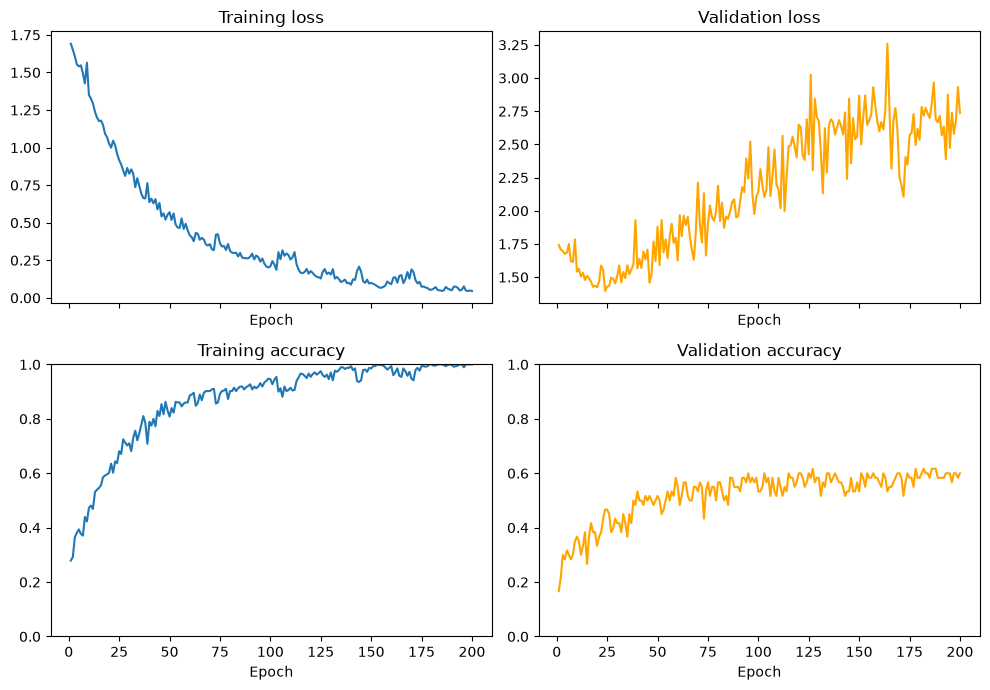

In [12]:
experiment_name = "GAT_baseline"

results_dir = Path("../results") / experiment_name
results_dir.mkdir(parents=True, exist_ok=True)

results = {
    "model": type(model).__name__,
    "learning_rate": optimizer.param_groups[0]["lr"],
    "best_epoch": best_epoch,
    "val_accuracy": best_val_accuracy,
    "test_accuracy": test_accuracy,
}

file_path = results_dir / f"{results['model']}.json"

file_path.write_text(json.dumps(results, indent=2), encoding="utf-8")

epoch_numbers = range(1, len(train_losses) + 1)

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)

axes[0, 0].plot(epoch_numbers, train_losses)
axes[0, 0].set_title("Training loss")

axes[0, 1].plot(epoch_numbers, val_losses, color="orange")
axes[0, 1].set_title("Validation loss")

axes[1, 0].plot(epoch_numbers, train_accuracies)
axes[1, 0].set_title("Training accuracy")
axes[1, 0].set_ylim(0, 1)

axes[1, 1].plot(epoch_numbers, val_accuracies, color="orange")
axes[1, 1].set_title("Validation accuracy")
axes[1, 1].set_ylim(0, 1)

for ax in axes.flat:
    ax.set_xlabel("Epoch")

plt.tight_layout()
fig.savefig(results_dir / "training.png", dpi=150)
plt.show()